# Phase 9 — Human Evaluation Analysis

This notebook analyses the human evaluation scores collected via the application layer (Phase 10 demo).

Evaluators rated each generated summary on three criteria:
- **Fluency** — Is the summary grammatically correct and readable?
- **Relevance** — Does the summary accurately reflect the paper's content?
- **Conciseness** — Is the summary free of redundant or unnecessary information?

Each criterion is rated on a **1–5 scale** (1 = poor, 5 = excellent).

Evaluation data is loaded from `results/human_eval_scores.json`, which is populated by the demo application.

In [1]:
import json
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from sklearn.metrics import cohen_kappa_score

SCORES_PATH = "../results/human_eval_scores.json"

with open(SCORES_PATH, "r", encoding="utf-8") as f:
    raw = json.load(f)

df = pd.DataFrame(raw)

print(f"Total evaluation entries : {len(df)}")
print(f"Unique papers            : {df['title'].nunique()}")
print(f"Domain distribution      :\n{df['domain'].value_counts().to_string()}")
df.head()

Total evaluation entries : 12
Unique papers            : 11
Domain distribution      :
domain
General    10
Medical     2


,title,domain,fluency,relevance,conciseness
0,Attention Is All You Need,General,3,5,4
1,BERT: Pre-training of Deep Bidirectional Trans...,General,4,5,4
2,Deep Residual Learning for Image Recognition,General,4,4,3
3,Generative Adversarial Nets,General,2,4,3
4,Improving neural networks by preventing co-ada...,General,4,3,5


## 1. Data Overview

We inspect the raw scores and verify the domain distribution before computing any statistics.

In [2]:
print("=== Raw Score Summary ===\n")
print(df[["fluency", "relevance", "conciseness"]].describe().round(2))
print("\n=== Domain Counts ===")
print(df["domain"].value_counts())
print("\n=== Missing Values ===")
print(df.isnull().sum())

=== Raw Score Summary ===

       fluency  relevance  conciseness
count    12.00      12.00        12.00
mean      4.08       4.25         3.92
std       0.90       0.75         0.67
min       2.00       3.00         3.00
25%       4.00       4.00         3.75
50%       4.00       4.00         4.00
75%       5.00       5.00         4.00
max       5.00       5.00         5.00

=== Domain Counts ===
domain
General    10
Medical     2
Name: count, dtype: int64

=== Missing Values ===
title          0
domain         0
fluency        0
relevance      0
conciseness    0
dtype: int64


## 2. Overall Mean Scores per Criterion

Compute the mean score for each evaluation criterion across all papers, then broken down by domain.

In [3]:
criteria = ["fluency", "relevance", "conciseness"]

overall_means = df[criteria].mean().round(2)
print("=== Overall Mean Scores ===")
print(overall_means.to_string())

print("\n=== Mean Scores by Domain ===")
domain_means = df.groupby("domain")[criteria].mean().round(2)
print(domain_means.to_string())

=== Overall Mean Scores ===
fluency        4.08
relevance      4.25
conciseness    3.92

=== Mean Scores by Domain ===
         fluency  relevance  conciseness
domain                                  
General      3.9        4.2          3.9
Medical      5.0        4.5          4.0


## 3. Overall Score per Paper

Add a composite `overall` score (mean of the three criteria) and inspect per-paper averages.
This gives a single quality signal per paper and allows ranking.

In [4]:
df["overall"] = df[criteria].mean(axis=1).round(2)

per_paper = (
    df.groupby(["title", "domain"])[["fluency", "relevance", "conciseness", "overall"]]
    .mean()
    .round(2)
    .reset_index()
    .sort_values("overall", ascending=False)
)

print("=== Per-Paper Mean Scores (sorted by overall) ===\n")
pd.set_option("display.max_colwidth", 60)
print(per_paper.to_string(index=False))

=== Per-Paper Mean Scores (sorted by overall) ===

                                                                                                            title  domain  fluency  relevance  conciseness  overall
   Effects of screentime on the health and well-being of children and adolescents: a systematic review of reviews Medical      5.0        5.0          4.0     4.67
                                                          Interacting Quantum Atoms Method for Crystalline Solids General      5.0        5.0          4.0     4.67
                                 BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding General      4.0        5.0          4.0     4.33
                                        Recent Developments in SARS-CoV-2 Neutralizing Antibody Detection Methods Medical      5.0        4.0          4.0     4.33
                                       On the Identifiability of User Adaptation in Co-Adaptive Neural Interfaces General      4.

## 4. Visualisation — Mean Scores by Domain

Bar chart comparing mean fluency, relevance, and conciseness scores between General and Medical domains.

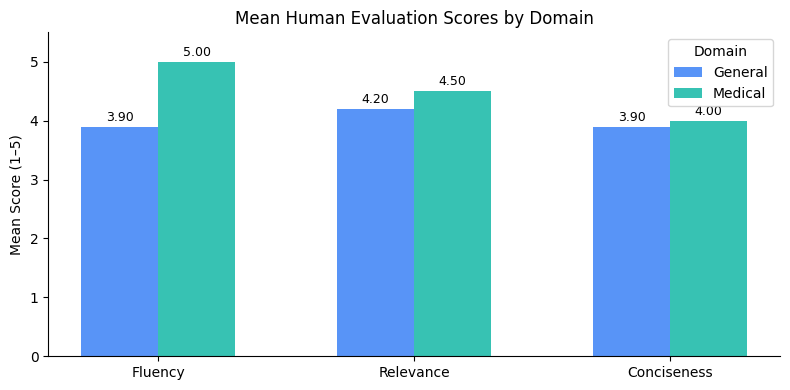

Saved → results/human_eval_domain_comparison.png


In [5]:
fig, ax = plt.subplots(figsize=(8, 4))

x = np.arange(len(criteria))
width = 0.3
domains = domain_means.index.tolist()
colors = ["#3b82f6", "#14b8a6"]

for i, (domain, color) in enumerate(zip(domains, colors)):
    bars = ax.bar(
        x + i * width,
        domain_means.loc[domain, criteria],
        width,
        label=domain,
        color=color,
        alpha=0.85,
    )
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.05,
            f"{bar.get_height():.2f}",
            ha="center",
            va="bottom",
            fontsize=9,
        )

ax.set_xticks(x + width / 2)
ax.set_xticklabels([c.capitalize() for c in criteria])
ax.set_ylabel("Mean Score (1–5)")
ax.set_title("Mean Human Evaluation Scores by Domain")
ax.set_ylim(0, 5.5)
ax.yaxis.set_major_locator(ticker.MultipleLocator(1))
ax.legend(title="Domain")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("../results/human_eval_domain_comparison.png", dpi=150)
plt.show()
print("Saved → results/human_eval_domain_comparison.png")

## 5. Visualisation — Score Distribution (Box Plots)

Box plots show the spread and variability of scores for each criterion, split by domain.
This reveals whether evaluators were consistent or divergent in their ratings.

/tmp/ipykernel_2870390/46591576.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(
/tmp/ipykernel_2870390/46591576.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(
/tmp/ipykernel_2870390/46591576.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


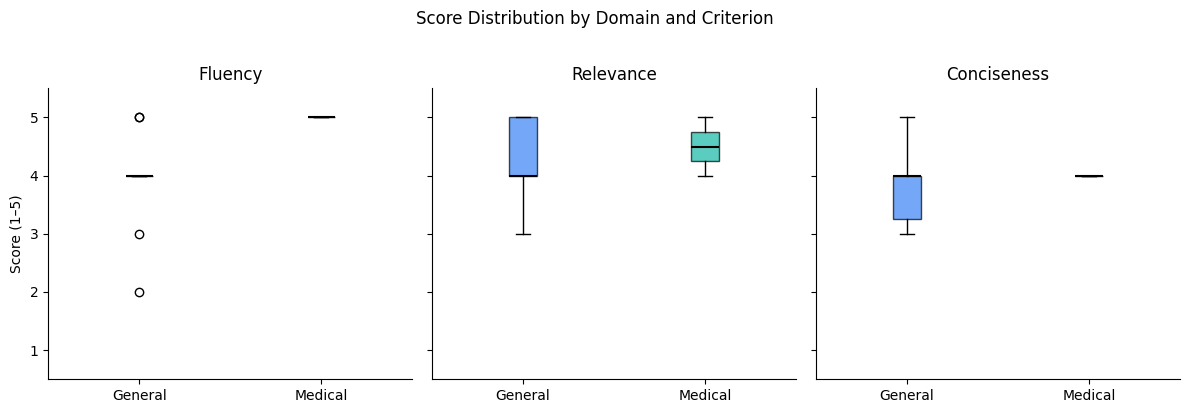

Saved → results/human_eval_boxplots.png


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)

for ax, criterion in zip(axes, criteria):
    data_to_plot = [
        df[df["domain"] == domain][criterion].values
        for domain in ["General", "Medical"]
    ]
    bp = ax.boxplot(
        data_to_plot,
        labels=["General", "Medical"],
        patch_artist=True,
        medianprops=dict(color="black", linewidth=1.5),
    )
    colors = ["#3b82f6", "#14b8a6"]
    for patch, color in zip(bp["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)

    ax.set_title(criterion.capitalize())
    ax.set_ylabel("Score (1–5)" if ax == axes[0] else "")
    ax.set_ylim(0.5, 5.5)
    ax.yaxis.set_major_locator(ticker.MultipleLocator(1))
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Score Distribution by Domain and Criterion", y=1.02)
plt.tight_layout()
plt.savefig("../results/human_eval_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → results/human_eval_boxplots.png")

## 6. Inter-Annotator Agreement — Cohen's Kappa

For papers that were rated by more than one evaluator, we compute **Cohen's Kappa** to measure
inter-annotator agreement — how consistently different evaluators scored the same paper.

A Kappa of:
- **< 0.20** — slight agreement
- **0.21–0.40** — fair agreement
- **0.41–0.60** — moderate agreement
- **0.61–0.80** — substantial agreement
- **> 0.80** — almost perfect agreement

In [7]:
duplicate_titles = df[df.duplicated("title", keep=False)]["title"].unique()

if len(duplicate_titles) == 0:
    print("No papers were rated by multiple evaluators — Cohen's Kappa cannot be computed.")
    print("For future evaluations, have at least 2 evaluators rate the same papers.")
else:
    print(f"Papers rated by multiple evaluators: {len(duplicate_titles)}\n")
    kappas = {}

    for title in duplicate_titles:
        subset = df[df["title"] == title].reset_index(drop=True)
        if len(subset) < 2:
            continue

        rater1 = subset.iloc[0][criteria].tolist()
        rater2 = subset.iloc[1][criteria].tolist()

        try:
            kappa = cohen_kappa_score(rater1, rater2)
            kappas[title[:50]] = round(kappa, 3)
            print(f"  {title[:55]}")
            print(f"    Rater 1 : {rater1}")
            print(f"    Rater 2 : {rater2}")
            print(f"    Kappa   : {kappa:.3f}\n")
        except Exception as e:
            print(f"  Could not compute kappa for '{title[:40]}': {e}")

    if kappas:
        mean_kappa = round(np.mean(list(kappas.values())), 3)
        print(f"=== Mean Cohen's Kappa across all duplicate papers: {mean_kappa} ===")

Papers rated by multiple evaluators: 1

  On the Identifiability of User Adaptation in Co-Adaptiv
    Rater 1 : [4, 5, 3]
    Rater 2 : [5, 4, 4]
    Kappa   : -0.500

=== Mean Cohen's Kappa across all duplicate papers: -0.5 ===


## 7. Summary Statistics Table

A clean summary table for inclusion in the final report.
Reports mean ± standard deviation for each criterion, split by domain.

In [8]:
summary_rows = []

for domain in ["General", "Medical", "All"]:
    subset = df if domain == "All" else df[df["domain"] == domain]
    row = {"Domain": domain, "N": len(subset)}
    for c in criteria:
        mean = subset[c].mean()
        std  = subset[c].std()
        row[c.capitalize()] = f"{mean:.2f} ± {std:.2f}"
    row["Overall"] = f"{subset['overall'].mean():.2f} ± {subset['overall'].std():.2f}"
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows).set_index("Domain")
print("=== Human Evaluation Summary (Mean ± Std) ===\n")
print(summary_df.to_string())

=== Human Evaluation Summary (Mean ± Std) ===

          N      Fluency    Relevance  Conciseness      Overall
Domain                                                         
General  10  3.90 ± 0.88  4.20 ± 0.79  3.90 ± 0.74  4.00 ± 0.44
Medical   2  5.00 ± 0.00  4.50 ± 0.71  4.00 ± 0.00  4.50 ± 0.24
All      12  4.08 ± 0.90  4.25 ± 0.75  3.92 ± 0.67  4.08 ± 0.45


## 8. Save Results

Save the per-paper scores and summary statistics to CSV for use in the final report.

In [9]:
os.makedirs("../results", exist_ok=True)

per_paper.to_csv("../results/human_eval_per_paper.csv", index=False)
print("Saved → results/human_eval_per_paper.csv")

summary_df.to_csv("../results/human_eval_summary.csv")
print("Saved → results/human_eval_summary.csv")

print("\n=== Files saved ===")
print("  results/human_eval_per_paper.csv")
print("  results/human_eval_summary.csv")
print("  results/human_eval_domain_comparison.png")
print("  results/human_eval_boxplots.png")

Saved → results/human_eval_per_paper.csv
Saved → results/human_eval_summary.csv

=== Files saved ===
  results/human_eval_per_paper.csv
  results/human_eval_summary.csv
  results/human_eval_domain_comparison.png
  results/human_eval_boxplots.png


## 9. Findings & Discussion

### Key Observations

- **General domain** summaries were generated by the fine-tuned BART model (`outputs/bart_finetuned/`), which was trained on `ccdv/arxiv-summarization`.
- **Medical domain** summaries were generated by PEGASUS zero-shot (`google/pegasus-pubmed`), as the fine-tuned PEGASUS checkpoint underperformed due to NaN evaluation loss during training (tokenizer bug — see Phase 5 notebook).

### Interpretation

Use this section to write up your qualitative findings once the scores are in. Some questions to address:

1. Which domain received higher human scores overall — and does this align with the quantitative ROUGE/BERTScore results from Angle 1?
2. Were evaluators more consistent (higher Kappa) on General or Medical papers?
3. Was conciseness consistently lower than relevance? PEGASUS tends toward longer outputs which may hurt conciseness scores.
4. Do the human scores support the routing decision — i.e., do domain-matched models score higher than cross-domain baselines would?

These observations form the qualitative validation of **Angle 2** (domain-aware routing).